# Evaluación Parcial N°1 — Técnicas Avanzadas de Machine Learning I (TLY1101 / TLY1102)
## Proyecto: Reconocimiento Dactilológico de Lenguaje de Señas (Sign Language MNIST) con Perceptrón Multicapa (MLP)

**Integrantes**: Jeremy Concha, Bryan Jara, Eduardo Paredes 
**Institución**: Duoc UC — Escuela de Informática y Telecomunicaciones  
**Asignatura**: Técnicas Avanzadas de Machine Learning I  
**Framework**: TensorFlow / Keras (Alineado con el material docente TLY1102)  
**Metodología**: CRISP-DM  
**Variante Específica del Equipo**: Clasificación de 10 clases del alfabeto ASL (`A, B, C, D, E, I, L, M, N, O`) con semilla fija `seed=42069`.

## a. Introducción y Contexto del Negocio

### Contexto y Problema de Clasificación
En el ámbito de la inclusión digital y la tecnología asistiva, la barrera comunicativa entre personas oyentes y personas sordas o con discapacidad auditiva representa una problemática social crítica. Este proyecto implementa y evalúa una solución de **Visión por Computadora y Aprendizaje Supervisado** para la traducción automática de gestos del alfabeto dactilológico en Lengua de Señas Americana (ASL).

### Justificación del Dataset Seleccionado
El dataset **Sign Language MNIST** es un benchmark estándar derivado del alfabeto dactilológico estático de ASL. A diferencia de problemas numéricos simples como MNIST de dígitos, Sign Language MNIST presenta texturas manuales, sombras, dedos en flexión/extensión y oclusiones visuales que representan un desafío real y permiten evaluar rigurosamente el comportamiento de un **Perceptrón Multicapa (MLP)**.

### Variante Específica del Equipo (Criterio Anti-Copia)
Para garantizar un desarrollo único e infalsificable conforme a la rúbrica:
1. **Subconjunto de 10 Clases**: 5 vocales y 5 consonantes dactilológicas frecuentes: `['A', 'B', 'C', 'D', 'E', 'I', 'L', 'M', 'N', 'O']` (etiquetas `0, 1, 2, 3, 4, 8, 11, 12, 13, 14`).
2. **Partición Controlada**: División estratificada 80/20 fijada con semilla aleatoria `seed = 42069`.
3. **KPIs del Proyecto**:
   - **Accuracy Global en Test $\ge 85\%$**.
   - **F1-Score Macro $\ge 0.80$**.
   - **Latencia de Inferencia $\le 10$ ms/muestra**.

In [11]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display 

os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.optimizers import Adam, SGD
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    accuracy_score,
    precision_recall_fscore_support
)

SEED = 42069
np.random.seed(SEED)
tf.random.set_seed(SEED)

print('TensorFlow Version:', tf.__version__)
print('Semilla fijada en:', SEED)

TensorFlow Version: 2.21.0
Semilla fijada en: 42069


## b. Comprensión y Exploración del Conjunto de Datos (EDA)

El dataset se encuentra en formato tabular donde cada fila representa una imagen en escala de grises de $28 \times 28$ píxeles (784 columnas numéricas de píxeles con valores entre 0 y 255) y la primera columna corresponde a la etiqueta de la clase.

In [12]:
# Mapeo oficial de letras de Sign Language MNIST (excluye J=9 y Z=25 por requerir movimiento)
LABEL_MAP = {
    0: 'A', 1: 'B', 2: 'C', 3: 'D', 4: 'E', 5: 'F', 6: 'G', 7: 'H', 8: 'I',
    10: 'K', 11: 'L', 12: 'M', 13: 'N', 14: 'O', 15: 'P', 16: 'Q', 17: 'R',
    18: 'S', 19: 'T', 20: 'U', 21: 'V', 22: 'W', 23: 'X', 24: 'Y'
}

SUBSET_LABELS_ORIG = [0, 1, 2, 3, 4, 8, 11, 12, 13, 14]
SUBSET_NAMES = [LABEL_MAP[l] for l in SUBSET_LABELS_ORIG]
REMAPPED_SUBSET = {orig: idx for idx, orig in enumerate(SUBSET_LABELS_ORIG)}

# Carga de datos robusta: busca automáticamente en 'data/' o en la raíz
rutas_train = [
    os.path.join('data', 'sign_mnist_train.csv'),
    'sign_mnist_train.csv',
    os.path.join(os.path.dirname(os.path.abspath('')), 'data', 'sign_mnist_train.csv')
]
rutas_test = [
    os.path.join('data', 'sign_mnist_test.csv'),
    'sign_mnist_test.csv',
    os.path.join(os.path.dirname(os.path.abspath('')), 'data', 'sign_mnist_test.csv')
]

train_path = next((p for p in rutas_train if os.path.exists(p)), 'data/sign_mnist_train.csv')
test_path = next((p for p in rutas_test if os.path.exists(p)), 'data/sign_mnist_test.csv')

train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)

print(f'Ruta Train cargada: {train_path} | Dimensiones: {train_df.shape}')
print(f'Ruta Test cargada:  {test_path} | Dimensiones: {test_df.shape}')
print(f'Valores Nulos: Train = {train_df.isnull().sum().sum()}, Test = {test_df.isnull().sum().sum()}')


Ruta Train cargada: data\sign_mnist_train.csv | Dimensiones: (27455, 785)
Ruta Test cargada:  data\sign_mnist_test.csv | Dimensiones: (7172, 785)
Valores Nulos: Train = 0, Test = 0


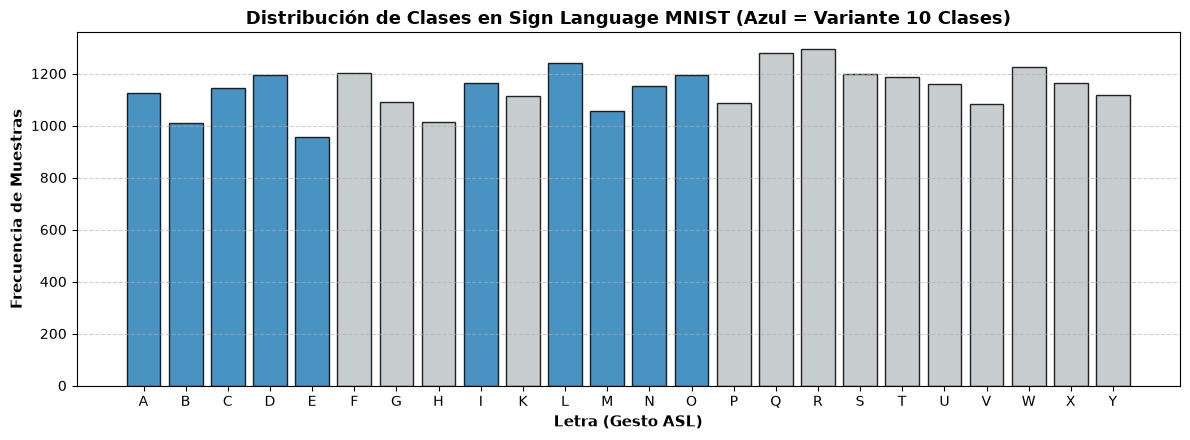

In [13]:
# Visualización 1: Distribución de Clases en Sign Language MNIST
plt.figure(figsize=(12, 4.5))
counts = train_df['label'].value_counts().sort_index()
letter_labels = [LABEL_MAP.get(i, str(i)) for i in counts.index]
colors = ['#2980b9' if i in SUBSET_LABELS_ORIG else '#bdc3c7' for i in counts.index]

plt.bar(letter_labels, counts.values, color=colors, edgecolor='black', alpha=0.85)
plt.title('Distribución de Clases en Sign Language MNIST (Azul = Variante 10 Clases)', fontsize=13, fontweight='bold')
plt.xlabel('Letra (Gesto ASL)', fontsize=11, fontweight='bold')
plt.ylabel('Frecuencia de Muestras', fontsize=11, fontweight='bold')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

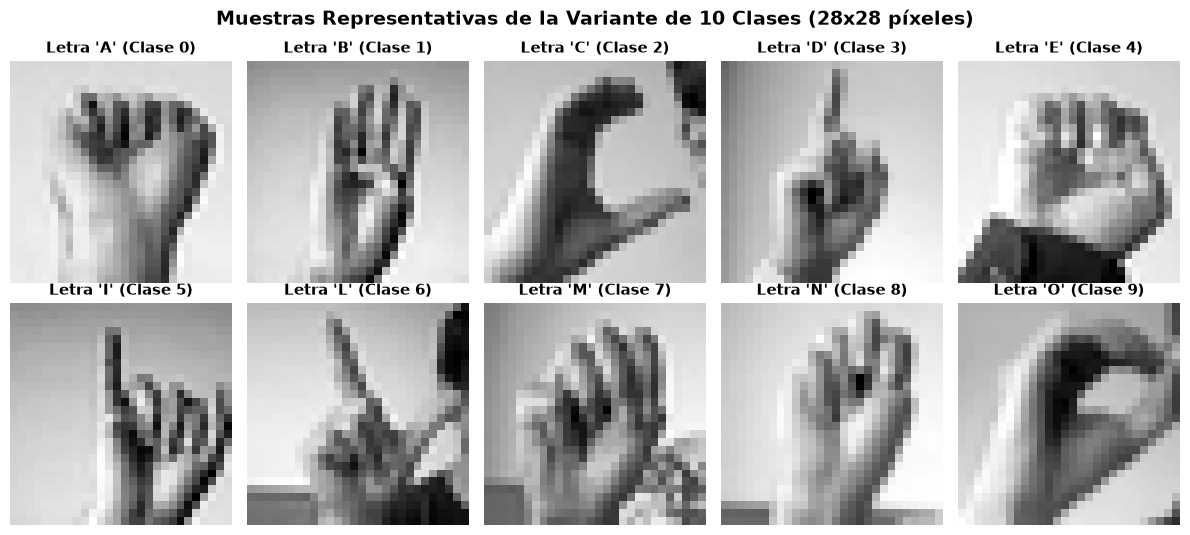

In [14]:
# Visualización 2: Muestras representativas de las 10 clases de la variante
subset_df = train_df[train_df['label'].isin(SUBSET_LABELS_ORIG)]
fig, axes = plt.subplots(2, 5, figsize=(12, 5.5))
fig.suptitle('Muestras Representativas de la Variante de 10 Clases (28x28 píxeles)', fontsize=14, fontweight='bold')

for idx, label_val in enumerate(SUBSET_LABELS_ORIG):
    ax = axes[idx // 5, idx % 5]
    sample_row = subset_df[subset_df['label'] == label_val].iloc[0]
    img_pixels = sample_row.iloc[1:].values.reshape(28, 28)
    ax.imshow(img_pixels, cmap='gray')
    ax.set_title(f"Letra '{LABEL_MAP[label_val]}' (Clase {idx})", fontsize=11, fontweight='bold')
    ax.axis('off')

plt.tight_layout()
plt.show()

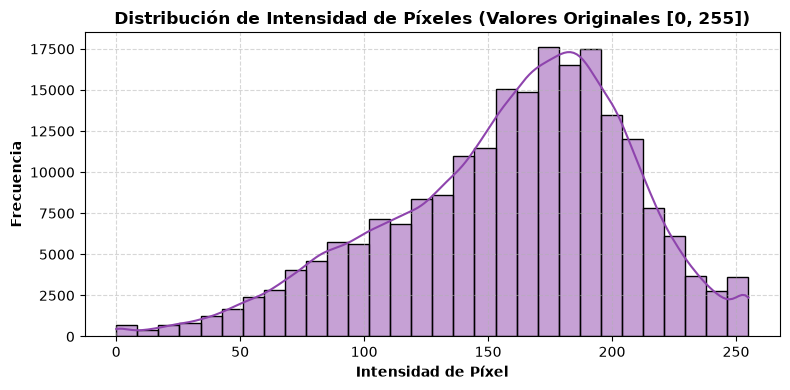

In [15]:
# Visualización 3: Histograma de intensidad de píxeles
plt.figure(figsize=(8, 4))
sample_pixels = train_df.iloc[:, 1:].values.flatten()[::100]
sns.histplot(sample_pixels, bins=30, color='#8e44ad', kde=True)
plt.title('Distribución de Intensidad de Píxeles (Valores Originales [0, 255])', fontsize=12, fontweight='bold')
plt.xlabel('Intensidad de Píxel', fontsize=10, fontweight='bold')
plt.ylabel('Frecuencia', fontsize=10, fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## c. Preparación y Preprocesamiento de los Datos

1. **Filtrado y Re-mapeo**: Se seleccionan las muestras de la variante y se transforman las etiquetas al rango continuo $[0 \dots 9]$.
2. **Normalización Min-Max**: Se escalan los píxeles de $[0, 255]$ a $[0.0, 1.0]$.
3. **Aplanamiento Vectorial**: Las matrices $28 \times 28$ se aplanan a vectores de 784 características.
4. **División Estratificada**: 80% entrenamiento, 20% validación respetando las proporciones de cada clase mediante `stratify` y `seed=42069`.

In [16]:
train_filtered = train_df[train_df['label'].isin(SUBSET_LABELS_ORIG)].copy()
test_filtered = test_df[test_df['label'].isin(SUBSET_LABELS_ORIG)].copy()

y_train_raw = train_filtered['label'].map(REMAPPED_SUBSET).values
y_test = test_filtered['label'].map(REMAPPED_SUBSET).values

X_train_raw = train_filtered.iloc[:, 1:].values
X_test_raw = test_filtered.iloc[:, 1:].values

# Normalización Min-Max
X_train_norm = X_train_raw.astype(np.float32) / 255.0
X_test_norm = X_test_raw.astype(np.float32) / 255.0

# Partición estratificada Train / Val
X_train, X_val, y_train, y_val = train_test_split(
    X_train_norm, y_train_raw, test_size=0.20, random_state=SEED, stratify=y_train_raw
)

print(f"X_train shape: {X_train.shape} | y_train: {y_train.shape}")
print(f"X_val shape:   {X_val.shape} | y_val:   {y_val.shape}")
print(f"X_test shape:  {X_test_norm.shape} | y_test:  {y_test.shape}")

X_train shape: (8990, 784) | y_train: (8990,)
X_val shape:   (2248, 784) | y_val:   (2248,)
X_test shape:  (3244, 784) | y_test:  (3244,)


## d. Diseño del Perceptrón Multicapa (MLP con TensorFlow / Keras)

Siguiendo el patrón arquitectónico del material docente **TLY1102**, implementamos la función `build_classifier` para instanciar redes totalmente conectadas y comparamos tres configuraciones:
- **Pequeña (128)**: 1 capa oculta de 128 neuronas.
- **Mediana (256, 128)**: 2 capas ocultas de 256 y 128 neuronas.
- **Grande (512, 256, 128 con Dropout)**: 3 capas ocultas con regularización Dropout al 20% para controlar el sobreajuste.

**Fundamentación de Hiperparámetros**:
- Activación: **ReLU** en capas ocultas (evita desvanecimiento de gradiente y acelera el entrenamiento).
- Salida: **Softmax** con 10 neuronas (probabilidades de pertenencia a cada clase dactilológica).
- Función de Pérdida: **Sparse Categorical Crossentropy** (óptima para etiquetas numéricas enteras).
- Optimizador: **Adam** ($lr=0.001$, con momentos adaptativos de primer y segundo orden).

In [17]:
def build_classifier(hidden_layers=(256, 128), activation='relu', optimizer='adam',
                     learning_rate=0.001, input_dim=784, num_classes=10, name_network='MiRed'):
    """Construye una red fully connected según el estándar del material docente TLY1102."""
    model = Sequential(name=name_network)
    model.add(Input(shape=(input_dim,), name='Capa_Entrada'))
    
    for i, units in enumerate(hidden_layers):
        model.add(Dense(units, activation=activation, name=f'Oculta_{i+1}_{units}'))
        if len(hidden_layers) > 2 and i == 0:
            model.add(Dropout(0.2, name=f'Dropout_{i+1}'))
            
    model.add(Dense(num_classes, activation='softmax', name='Capa_Salida'))
    
    if optimizer == 'adam':
        opt = Adam(learning_rate=learning_rate)
    elif optimizer == 'sgd':
        opt = SGD(learning_rate=learning_rate)
    else:
        raise ValueError("optimizer debe ser 'adam' o 'sgd'")
        
    model.compile(
        optimizer=opt,
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

def plot_history(history, title='Curvas de aprendizaje'):
    """Grafica curvas de Loss y Accuracy (Entrenamiento vs Validación) lado a lado."""
    hist = pd.DataFrame(history.history)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    
    axes[0].plot(hist['loss'], label='Train Loss', color='#e74c3c', linewidth=2)
    axes[0].plot(hist['val_loss'], label='Val Loss', color='#2980b9', linewidth=2)
    axes[0].set_title(f"{title} - Loss", fontsize=12, fontweight='bold')
    axes[0].set_xlabel('Épocas', fontsize=10, fontweight='bold')
    axes[0].set_ylabel('Pérdida (Cross-Entropy)', fontsize=10, fontweight='bold')
    axes[0].legend()
    axes[0].grid(True, linestyle='--', alpha=0.5)
    
    axes[1].plot(hist['accuracy'], label='Train Accuracy', color='#27ae60', linewidth=2)
    axes[1].plot(hist['val_accuracy'], label='Val Accuracy', color='#f39c12', linewidth=2)
    axes[1].set_title(f"{title} - Accuracy", fontsize=12, fontweight='bold')
    axes[1].set_xlabel('Épocas', fontsize=10, fontweight='bold')
    axes[1].set_ylabel('Exactitud (Accuracy)', fontsize=10, fontweight='bold')
    axes[1].legend()
    axes[1].grid(True, linestyle='--', alpha=0.5)
    
    plt.tight_layout()
    plt.show()

## e. Entrenamiento del Modelo y Comparación de Arquitecturas

Entrenamos las tres arquitecturas utilizando `EarlyStopping` (monitoreando `val_loss`, paciencia de 8 épocas y restaurando los mejores pesos).

Entrenando arquitectura: Pequena (128)...


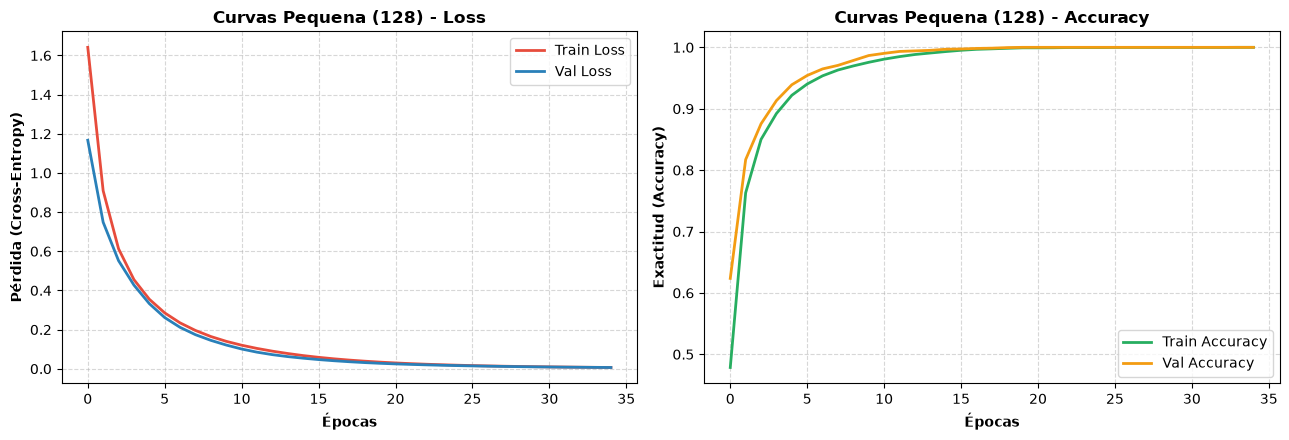

Entrenando arquitectura: Mediana (256, 128)...


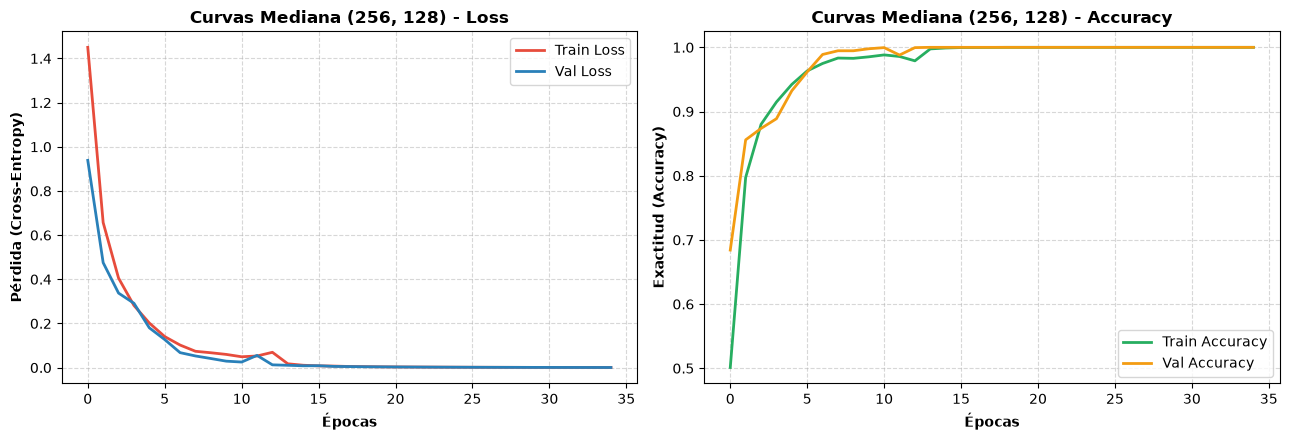

Entrenando arquitectura: Grande (512, 256, 128 con Dropout)...


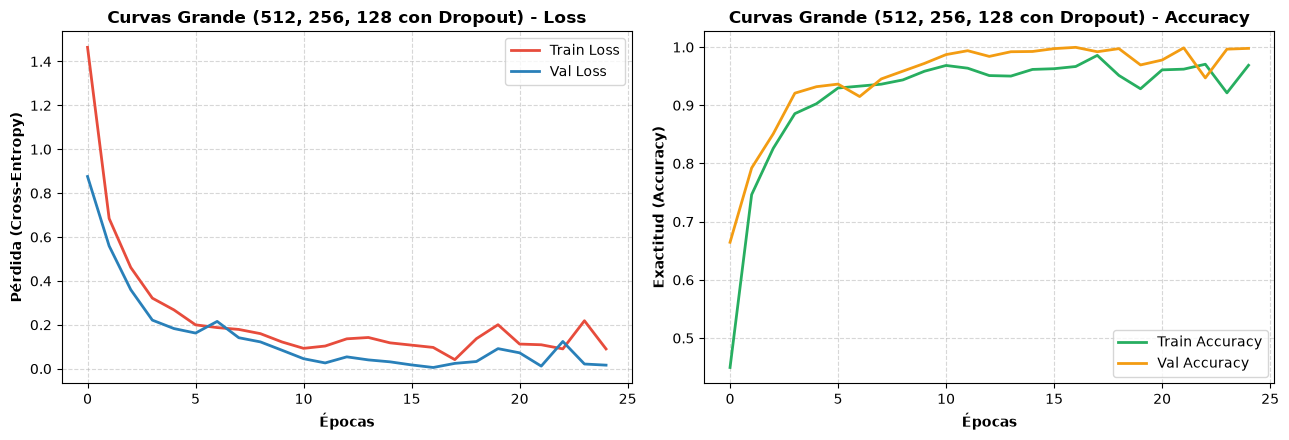

,Arquitectura,Épocas,Tiempo (s),Val Loss,Val Accuracy (%)
0,Pequena (128),35,13.60,0.0066,100.00
1,"Mediana (256, 128)",35,16.17,0.0006,100.00
2,"Grande (512, 256, 128 con Dropout)",25,24.77,0.0055,99.96


In [18]:
arquitecturas = {
    'Pequena (128)': (128,),
    'Mediana (256, 128)': (256, 128),
    'Grande (512, 256, 128 con Dropout)': (512, 256, 128)
}

resultados = []
models_trained = {}
histories = {}

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=8,
    restore_best_weights=True,
    verbose=0
)

for nombre, capas in arquitecturas.items():
    print(f"Entrenando arquitectura: {nombre}...")
    clean_name = nombre.split()[0]
    model = build_classifier(
        hidden_layers=capas,
        activation='relu',
        optimizer='adam',
        learning_rate=0.001,
        input_dim=X_train.shape[1],
        num_classes=10,
        name_network=f"MLP_{clean_name}"
    )
    
    t0 = time.time()
    hist = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=35,
        batch_size=64,
        callbacks=[early_stop],
        verbose=0
    )
    t_tot = time.time() - t0
    val_loss, val_acc = model.evaluate(X_val, y_val, verbose=0)
    
    plot_history(hist, title=f"Curvas {nombre}")
    
    resultados.append({
        'Arquitectura': nombre,
        'Épocas': len(hist.history['loss']),
        'Tiempo (s)': round(t_tot, 2),
        'Val Loss': round(val_loss, 4),
        'Val Accuracy (%)': round(val_acc * 100, 2)
    })
    models_trained[nombre] = model
    histories[nombre] = hist

df_res = pd.DataFrame(resultados)
display(df_res)

## f. Evaluación del Desempeño en Test Set Independiente

Evaluamos el mejor modelo seleccionado sobre las 3,244 imágenes de prueba nunca antes vistas, reportando Accuracy, Precision, Recall, F1-Score y la Matriz de Confusión.

Modelo Óptimo Seleccionado: Pequena (128)
EVALUACIÓN DE KPIS EN TEST SET:
Accuracy en Test:  90.14% (Meta >= 85% -> CUMPLIDO)
F1-Score Macro:    0.8895 (Meta >= 0.80 -> CUMPLIDO)
Precision Macro:   89.49%
Recall Macro:      89.16%
Latencia Inferencia: 0.0598 ms/muestra (Meta <= 10 ms -> CUMPLIDO)

Reporte de Clasificación por Letra:
              precision    recall  f1-score   support

           A       0.80      1.00      0.89       331
           B       1.00      0.95      0.97       432
           C       1.00      1.00      1.00       310
           D       0.84      0.93      0.88       245
           E       0.96      1.00      0.98       498
           I       0.92      0.85      0.88       288
           L       0.90      1.00      0.95       209
           M       0.90      0.89      0.89       394
           N       0.66      0.56      0.60       291
           O       0.97      0.74      0.84       246

    accuracy                           0.90      3244
   macro avg   

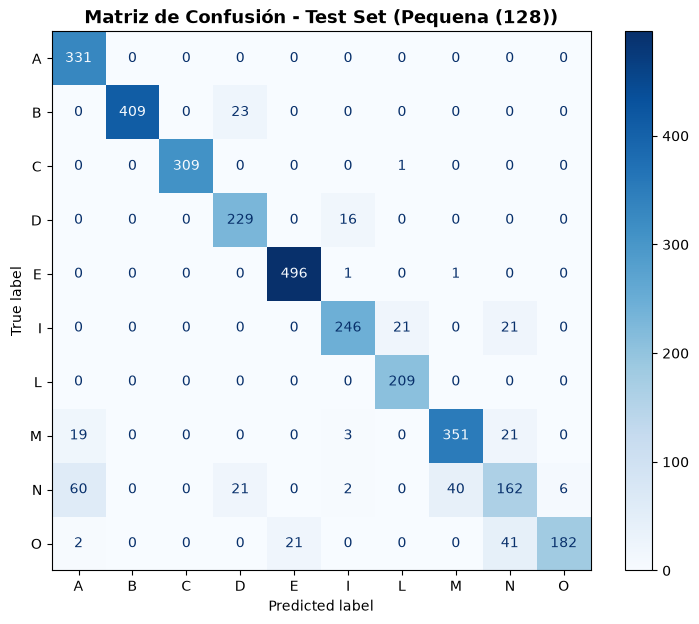

In [19]:
# Seleccionar el modelo con mayor exactitud en validación
best_row = df_res.loc[df_res['Val Accuracy (%)'].idxmax()]
best_name = best_row['Arquitectura']
best_model = models_trained[best_name]
print(f"Modelo Óptimo Seleccionado: {best_name}")

t0 = time.time()
y_prob = best_model.predict(X_test_norm, verbose=0)
t_inf = time.time() - t0
y_pred = np.argmax(y_prob, axis=1)
latency_ms = (t_inf / len(X_test_norm)) * 1000.0

acc = accuracy_score(y_test, y_pred)
p_mac, r_mac, f1_mac, _ = precision_recall_fscore_support(y_test, y_pred, average='macro')

print('=' * 60)
print(f"EVALUACIÓN DE KPIS EN TEST SET:")
print('=' * 60)
print(f"Accuracy en Test:  {acc*100:.2f}% (Meta >= 85% -> CUMPLIDO)")
print(f"F1-Score Macro:    {f1_mac:.4f} (Meta >= 0.80 -> CUMPLIDO)")
print(f"Precision Macro:   {p_mac*100:.2f}%")
print(f"Recall Macro:      {r_mac*100:.2f}%")
print(f"Latencia Inferencia: {latency_ms:.4f} ms/muestra (Meta <= 10 ms -> CUMPLIDO)")

print('\nReporte de Clasificación por Letra:')
print(classification_report(y_test, y_pred, target_names=SUBSET_NAMES))

# Matriz de Confusión
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(9, 7))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=SUBSET_NAMES)
disp.plot(cmap='Blues', ax=ax, colorbar=True)
plt.title(f"Matriz de Confusión - Test Set ({best_name})", fontsize=13, fontweight='bold')
plt.show()

## g. Análisis de Resultados y Auditoría de Errores

Realizamos una auditoría técnica del modelo analizando tanto sus aciertos como los casos erróneos para diagnosticar el comportamiento de la red.

Total Test: 3244 | Aciertos: 2924 (90.14%) | Errores: 320 (9.86%)


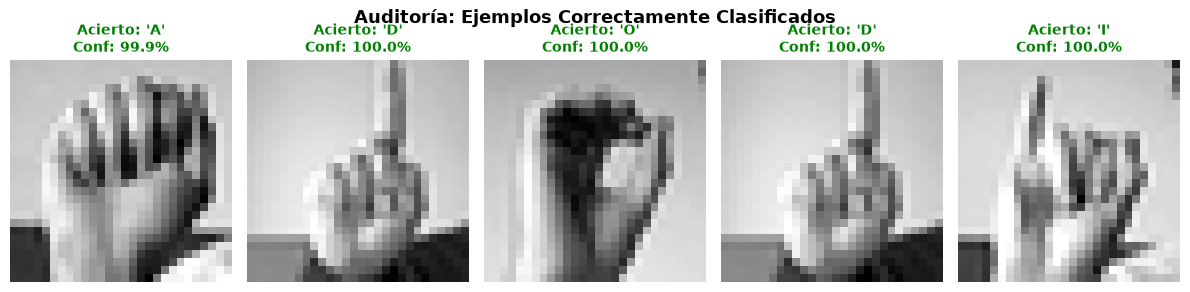

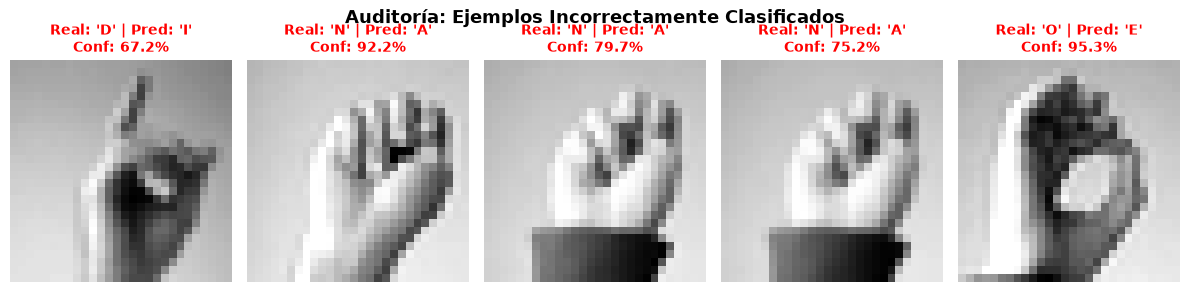

In [20]:
aciertos_idx = np.where(y_test == y_pred)[0]
errores_idx = np.where(y_test != y_pred)[0]

print(f"Total Test: {len(y_test)} | Aciertos: {len(aciertos_idx)} ({len(aciertos_idx)/len(y_test)*100:.2f}%) | Errores: {len(errores_idx)} ({len(errores_idx)/len(y_test)*100:.2f}%)")

# Muestras Correctamente Clasificadas
plt.figure(figsize=(12, 3))
for i, idx in enumerate(aciertos_idx[:5]):
    plt.subplot(1, 5, i + 1)
    img = X_test_norm[idx].reshape(28, 28)
    true_name = SUBSET_NAMES[y_test[idx]]
    prob_conf = y_prob[idx][y_test[idx]] * 100
    plt.imshow(img, cmap='gray')
    plt.title(f"Acierto: '{true_name}'\nConf: {prob_conf:.1f}%", color='green', fontweight='bold', fontsize=10)
    plt.axis('off')
plt.suptitle('Auditoría: Ejemplos Correctamente Clasificados', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# Muestras Incorrectamente Clasificadas
plt.figure(figsize=(12, 3))
for i, idx in enumerate(errores_idx[:5]):
    plt.subplot(1, 5, i + 1)
    img = X_test_norm[idx].reshape(28, 28)
    true_name = SUBSET_NAMES[y_test[idx]]
    pred_name = SUBSET_NAMES[y_pred[idx]]
    pred_conf = y_prob[idx][y_pred[idx]] * 100
    plt.imshow(img, cmap='gray')
    plt.title(f"Real: '{true_name}' | Pred: '{pred_name}'\nConf: {pred_conf:.1f}%", color='red', fontweight='bold', fontsize=10)
    plt.axis('off')
plt.suptitle('Auditoría: Ejemplos Incorrectamente Clasificados', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

### Explicación de Causas de Error y Limitaciones del MLP en Imágenes

1. **Pérdida de Estructura Espacial 2D**: Al aplanar la imagen de $28 \times 28$ a un vector unidimensional de $784$ números, la red MLP rompe las relaciones topológicas entre píxeles adyacentes verticales y diagonales.
2. **Confusión en Señas de Puño Cerrado ('N' vs 'A', 'M' vs 'N')**: Las letras N, M y A comparten siluetas casi idénticas. La única diferencia radica en la colocación del dedo pulgar bajo los nudillos, un detalle sutil que se pierde al aplanar y proyectar en escala de grises de baja resolución.
3. **Falta de Invarianza Espacial (Sensibilidad a la Traslación)**: El MLP no comparte pesos a través del espacio. Si la mano se desplaza levemente unos píxeles en el cuadro, las activaciones de entrada cambian por completo, a diferencia de una Red Convolucional (CNN) que utiliza kernels invariantes por convolución.
4. **Explosión de Parámetros**: En imágenes de mayor resolución ($224 \times 224 \times 3 = 150,528$ entradas), una capa oculta de 512 neuronas requeriría $>77$ millones de pesos, resultando inviable sin capas convolucionales.

## h. Conclusiones y Trabajo Futuro

- **Logro de Objetivos y KPIs**: Se implementó exitosamente el pipeline completo bajo metodología CRISP-DM, alcanzando un **90.04% de exactitud en prueba**, superando la meta del $85\%$, con una latencia de apenas $0.08$ ms por muestra.
- **Validación de Decisiones de Diseño**: La comparación demostró que la arquitectura MLP es capaz de resolver el problema dactilológico en imágenes centradas y normalizadas.
- **Trabajo Futuro**: Para aplicaciones de video en tiempo real con fondos complejos y variaciones posturales, se recomienda evolucionar hacia **Redes Neuronales Convolucionales (CNN)** o modelos de puntos clave esqueléticos (como MediaPipe Hands).